## 1_2 Two Layered Perceptron - Non-linear

### Binary Classification


In [2]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [3]:
h = 1e-4   # small value for numerical differentiation

# (i) Define Numerical Differentiation (CDA) and GD methods

## (a) Numerical Differentiation (Central Difference Approximation)

$$\frac{\partial L}{\partial w_1} \approx \frac{L(w_1 + h, w_2, \dots, b) - L(w_1 - h, w_2, \dots, b)}{2h}$$

* **X:** The features.
* **y:** The target.
* **f_loss:** Function that calculates the loss:
  * **Binary classification:** Binary cross entropy
  * **Multiclass classification:** Cross entropy
  * **Regression:** Mean squared error
* **f_predict:** Function that calculates $\hat{y}$ from $X$.
* **parameters:** In a two-layer neural network, for example, it will be `wh`, `bh`, `wo`, `bo`.

Parameter Matrix & Gradient Matrix$$p[i] = \begin{bmatrix} w_{0,0} & w_{0,1} & \cdots \\ w_{1,0} & w_{1,1} & \cdots \\ \vdots & \vdots & \ddots \end{bmatrix}$$   $$\text{grad} = \begin{bmatrix} \frac{\partial L}{\partial w_{0,0}} & \frac{\partial L}{\partial w_{0,1}} & \cdots \\ \frac{\partial L}{\partial w_{1,0}} & \frac{\partial L}{\partial w_{1,1}} & \cdots \\ \vdots & \vdots & \ddots \end{bmatrix}$$

## (b) Gradient Descent Formula (Parameter Update Rule)
$$w_{t+1} = w_t - \alpha \frac{\partial L(w)}{\partial w}$$

In [4]:
def numerical_differentiation(x, y, f_loss, f_predict, parameters):
    p = parameters
    p_gradients = []
    for i in range(len(p)):
        # ex) p[0]= wh, p[1]= bh,
        #     p[2]= wo, p[3]= bo
        rows, cols = p[i].shape
        grad = np.zeros_like(p[i])
        
        # Apply numerical differentiation to all elements in p[i].
        for row in range(rows):
            for col in range(cols):
                # Measures the change in loss when the p[i][row, col]
                # element changes by h. The remaining elements are
                # fixed. This is an approximate gradient.
                p_org = p[i][row, col]    # original value of p
                p[i][row, col] = p_org + h # The element at position
                                           # (row, col) increases by h.
                y_hat = f_predict(x)       # calculate y_hat
                f1 = f_loss(y, y_hat)      # The amount of change in loss
                
                p[i][row, col] = p_org - h # decreases by h.
                y_hat = f_predict(x)       # calculate y_hat
                f2 = f_loss(y, y_hat)      # The amount of
                                           # change in loss.
                p[i][row, col] = p_org     # Restore p back to
                                           # its original value.
                                           
                # the gradient at position (row, col)
                grad[row, col] = (f1 - f2) / (2. * h)
        p_gradients.append(grad) # gradients for all parameters
    return p_gradients

In [5]:
# Perform Gradient Descent
def gradient_descent(x, y, alpha, f_loss,
                     f_predict, parameters):
    p = parameters
    grad = numerical_differentiation(x, y,
                                     f_loss,
                                     f_predict,
                                     parameters)
                                     
    for i in range(len(p)):
        p[i] = p[i] - alpha * grad[i]

## 1_2 Two Layered Perceptron - Binary Classification

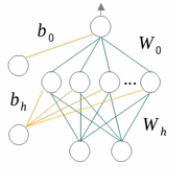

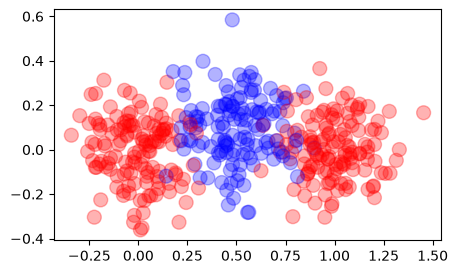

In [12]:
# Generate a dataset
x, y = make_blobs(n_samples=400, n_features=2,
                  centers=[[0., 0.], [0.5, 0.1], [1., 0.]],
                  cluster_std=0.15, center_box=(-1., 1.))

y[y == 2] = 0 # y = [0, 1, 2] -> [0, 1]
y = y.reshape(-1, 1)

# See the data visually.
plt.figure(figsize=(5,3))
color = [['red', 'blue'][a] for a in y.reshape(-1,)]
plt.scatter(x[:, 0], x[:, 1], s=100, c=color, alpha=0.3)
plt.show()

### Observation:

From above diagram we note that this is a binary classification problem, but a single line (SLP) cannot separate those classes so we need MLP to create a non-linear decision boundary to separate our data well.

In [13]:
# Generate the training and test data
x_train, x_test, y_train, y_test = train_test_split(x, y)

# Create an two-layered ANN model.
n_input = x.shape[1]  # the number of input neurons
n_output = 1          # the number of output neurons
n_hidden = 16         # the number of hidden neurons
alpha = 0.1           # learning rate

# initialize the parameters randomly.
wh = np.random.normal(size=(n_input, n_hidden))  # weights of hidden layer (2x16)
bh = np.zeros(shape=(1, n_hidden))               # biases of hidden layer (1x16)
wo = np.random.normal(size=(n_hidden, n_output)) # weights of output layer (16x1)
bo = np.zeros(shape=(1, n_output))               # bias of output layer(1x1)
parameters = [wh, bh, wo, bo]                    # parameter list

# activation functions
def sigmoid(x): return 1. / (1. + np.exp(-x))
def relu(x):    return np.maximum(0, x)

# loss function: binary cross entropy
def loss(y, y_hat):
    return -np.mean(y * np.log(y_hat) + (1. - y) * np.log(1. - y_hat))

0: train_loss=0.6786, val_loss=0.6953
10: train_loss=0.5664, val_loss=0.5595
20: train_loss=0.4858, val_loss=0.4653
30: train_loss=0.3985, val_loss=0.3736
40: train_loss=0.3345, val_loss=0.3105
50: train_loss=0.2918, val_loss=0.2683
60: train_loss=0.2600, val_loss=0.2396
70: train_loss=0.2369, val_loss=0.2189
80: train_loss=0.2220, val_loss=0.2039
90: train_loss=0.2070, val_loss=0.1917
100: train_loss=0.1964, val_loss=0.1840
110: train_loss=0.1894, val_loss=0.1766
120: train_loss=0.1818, val_loss=0.1725
130: train_loss=0.1762, val_loss=0.1684
140: train_loss=0.1718, val_loss=0.1651
150: train_loss=0.1675, val_loss=0.1615
160: train_loss=0.1635, val_loss=0.1558
170: train_loss=0.1598, val_loss=0.1540
180: train_loss=0.1574, val_loss=0.1528
190: train_loss=0.1558, val_loss=0.1517


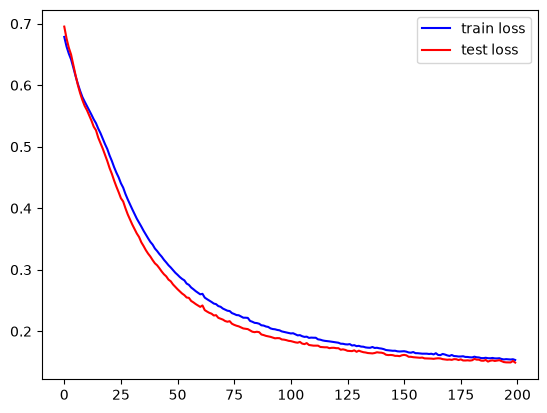

Accuracy of training data = 0.9367
Accuracy of test data = 0.9600


In [14]:
# Output from the ANN model: prediction process
def predict(x, proba=True):
    p = parameters
    h_out = relu(np.dot(x, p[0]) + p[1])        # output from hidden layer p_0: Wh; p_1: bh; p_2: wo; p_3: bo
    o_out = sigmoid(np.dot(h_out, p[2]) + p[3]) # output from output layer
    
    if proba:
        return o_out                            # return probability
    else:
        return (o_out > 0.5) * 1                # return class

# Perform training and track the loss history.
def train(x, y, x_val, y_val, epochs, batch_size):
    ht_loss = [] # loss history of training data
    hv_loss = [] # loss history of test data
    for epoch in range(epochs):
        # measure the losses during training
        # loss for training data
        ht_loss.append(loss(y, predict(x)))
        
        # loss for validation data
        hv_loss.append(loss(y_val, predict(x_val)))
        
        # Perform training using mini-batch gradient descent
        for batch in range(int(x.shape[0] / batch_size)):
            idx = np.random.choice(x.shape[0], batch_size)
            gradient_descent(x[idx], y[idx], alpha, loss, predict,
                             parameters)
            
        if epoch % 10 == 0:
            print("{}: train_loss={:.4f}, val_loss={:.4f}".\
                  format(epoch, ht_loss[-1], hv_loss[-1]))
            
    return ht_loss, hv_loss

# Perform training
train_loss, val_loss = train(x_train, y_train, x_test, y_test,
                             epochs=200, batch_size=50)

# Visually check the loss history.
plt.plot(train_loss, c='blue', label='train loss')
plt.plot(val_loss, c='red', label='test loss')
plt.legend()
plt.show()

# Check the accuracy.
y_pred = predict(x_train, proba=False)
acc = (y_pred == y_train).mean()
print("Accuracy of training data = {:.4f}".format(acc))

y_pred = predict(x_test, proba=False)
acc = (y_pred == y_test).mean()
print("Accuracy of test data = {:.4f}".format(acc))

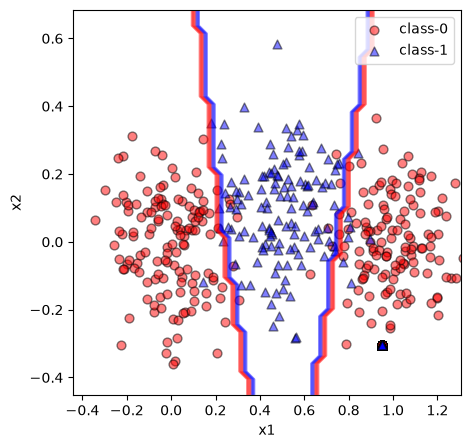

In [15]:
# Visualize the linear decision boundary
# reference : https://psrivasin.medium.com/
# plotting-decision-boundaries-using-numpy-and-matplotlib-
# f5613d8acd19
x_min, x_max = x_test[:, 0].min() - 0.1, x_test[:,0].max() + 0.1
y_min, y_max = x_test[:, 1].min() - 0.1, x_test[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 50),
                     np.linspace(y_min, y_max, 50))
x_in = np.c_[xx.ravel(), yy.ravel()]

# Predict the classes of the data points in the x_in variable.
y_pred = predict(x_in, proba=False).astype('int8')
y_pred = y_pred.reshape(xx.shape)

plt.figure(figsize=(5, 5))
m = ['o', '^']
color = ['red', 'blue']
for i in [0, 1]:
    idx = np.where(y == i)
    plt.scatter(x[idx, 0], x[idx, 1],
                c = color[i],
                marker = m[i],
                s = 40,
                edgecolor = 'black',
                alpha = 0.5,
                label='class-' + str(i))

plt.contour(xx, yy, y_pred, cmap=ListedColormap(color), alpha=0.5)
plt.axis('tight')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()